# Task 2: Exploratory Data Analysis

This notebook uses the Superstore sample to inspect data quality, explore sales and profit, and summarize patterns.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving superstore_sample.csv to superstore_sample (1).csv


In [ ]:
import pandas as pd
import numpy as np
df=pd.read_csv("superstore_sample.csv")

## 1. Understand the data

The dataset has 2,025 rows and 15 columns before cleaning. It contains order dates, customer and product details, sales, quantity, discount, and profit. Dates span 2022–2025.


In [ ]:
print("Shape:\n", df.shape)

Shape:
 (2025, 15)


In [ ]:
print("Columns:\n",df.columns)

Columns:
 Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Segment', 'Region', 'State', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')


In [ ]:
print("Missing Values:")
print(df.isna().sum())


Missing Values:
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Segment         10
Region           0
State           12
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount        20
Profit          16
dtype: int64


In [ ]:
print("\nDuplicate rows count:", df.duplicated().sum())


Duplicate rows count: 25


In [ ]:
print("\nData Types:")
print(df.dtypes)


Data Types:
Order ID         object
Order Date       object
Ship Date        object
Ship Mode        object
Customer ID      object
Segment          object
Region           object
State            object
Category         object
Sub-Category     object
Product Name     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


## 2. Clean the data

Dates are converted to datetime. Exact duplicates are removed. Blank discounts are treated as zero; missing Segment and State values are labeled `Unknown`. Missing Profit is kept blank so we do not invent profit values. The next cell prints the cleaning log.


In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d-%m-%Y', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d-%m-%Y', errors='coerce')

In [ ]:
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates()
df['Discount'] = df['Discount'].fillna(0.0)
df['Segment'] = df['Segment'].fillna('Unknown')
df['State'] = df['State'].fillna('Unknown')
print('Duplicate rows removed:', duplicate_count)
print('Cleaning complete. Missing Profit values are kept blank and excluded from profit summaries.')


Duplicate rows removed: 25
Cleaning complete. Missing Profit values are kept blank and excluded from profit summaries.


In [ ]:
df.columns.tolist()

['Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Segment',
 'Region',
 'State',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

## 3. Univariate analysis

The histograms show the distributions of Sales, Profit, and Quantity. The category, region, and segment counts show how order rows are spread across groups.


In [ ]:
df[["Sales","Profit","Quantity"]].describe()

,Sales,Profit,Quantity
count,2000.000000,1985.000000,2000.000000
mean,947.434630,79.356695,3.488000
std,1712.089767,431.040120,2.278256
min,4.500000,-1330.320000,1.000000
25%,80.327500,-13.410000,2.000000
50%,265.185000,9.280000,3.000000
75%,968.415000,44.880000,5.000000
max,14698.410000,4961.400000,10.000000


### Potential outliers

The IQR rule below flags unusually low or high values for review. A flag does not mean the value is wrong, so keep it unless you find evidence of a data error.


In [ ]:
for col in ['Sales', 'Profit', 'Quantity']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {flagged} potential outliers')


Sales: 235 potential outliers
Profit: 451 potential outliers
Quantity: 33 potential outliers


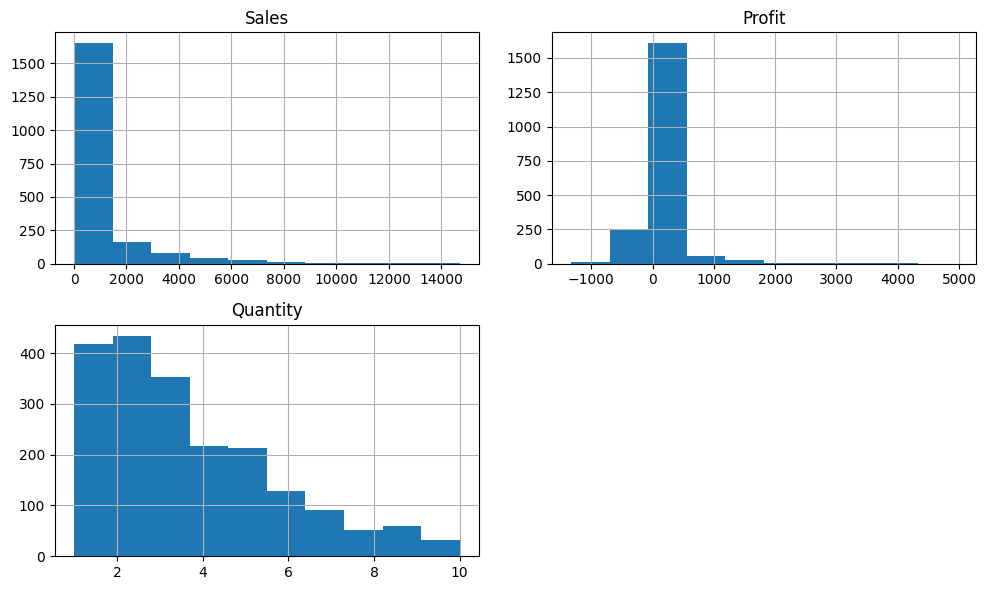

In [ ]:
import matplotlib.pyplot as plt
df[["Sales","Profit","Quantity"]].hist( figsize=(10, 6))
plt.tight_layout()
plt.show()

In [ ]:
for column in ["Category", "Region", "Segment"]:
    print(f"\n{column} counts:")
    print(df[column].value_counts(dropna=False))


Category counts:
Category
Technology         689
Office Supplies    662
Furniture          649
Name: count, dtype: int64

Region counts:
Region
West       645
East       530
Central    467
South      358
Name: count, dtype: int64

Segment counts:
Segment
Consumer       1033
Corporate       625
Home Office     332
Unknown          10
Name: count, dtype: int64


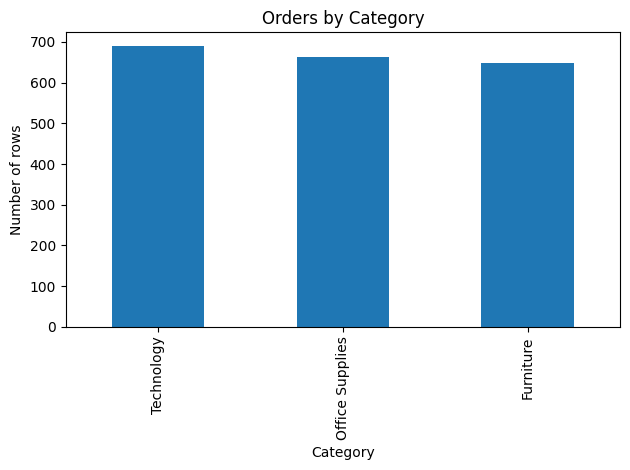

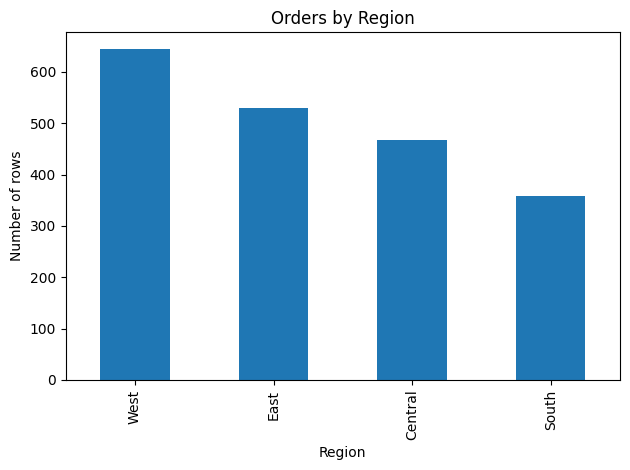

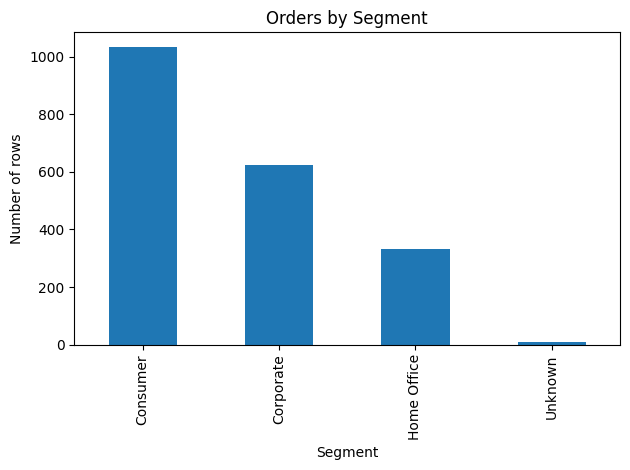

In [ ]:
for column in ["Category", "Region", "Segment"]:
    df[column].value_counts(dropna=False).plot(kind="bar", title=f"Orders by {column}")
    plt.ylabel("Number of rows")
    plt.tight_layout()
    plt.show()

## 4. Bivariate analysis

The scatter plot compares Sales and Profit. The box plot compares Profit across discount levels. These charts show relationships, not proof that one variable causes another.


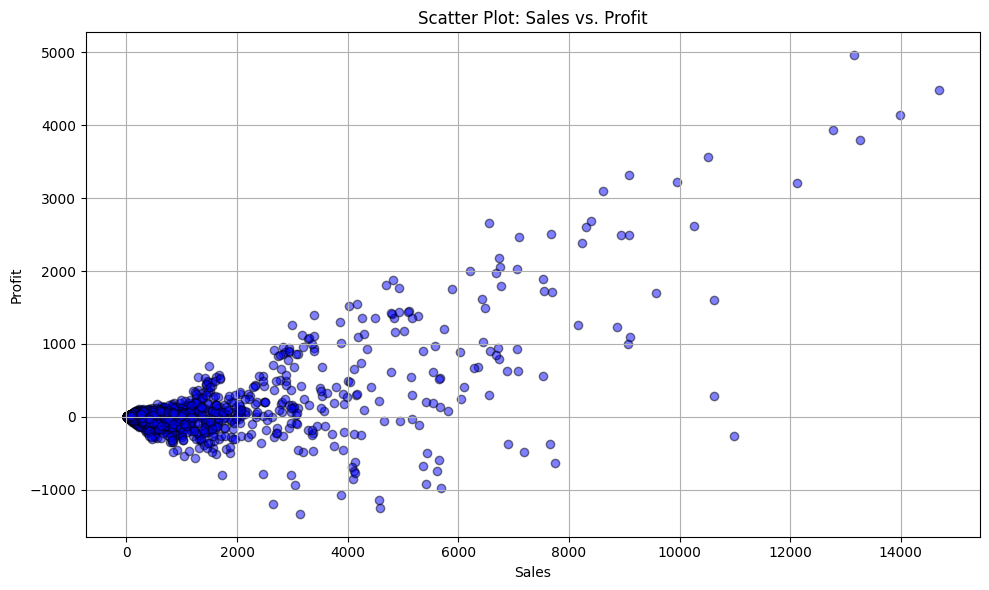

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df['Sales'], df['Profit'],alpha=0.5, color='blue', edgecolors='black')
plt.title('Scatter Plot: Sales vs. Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()

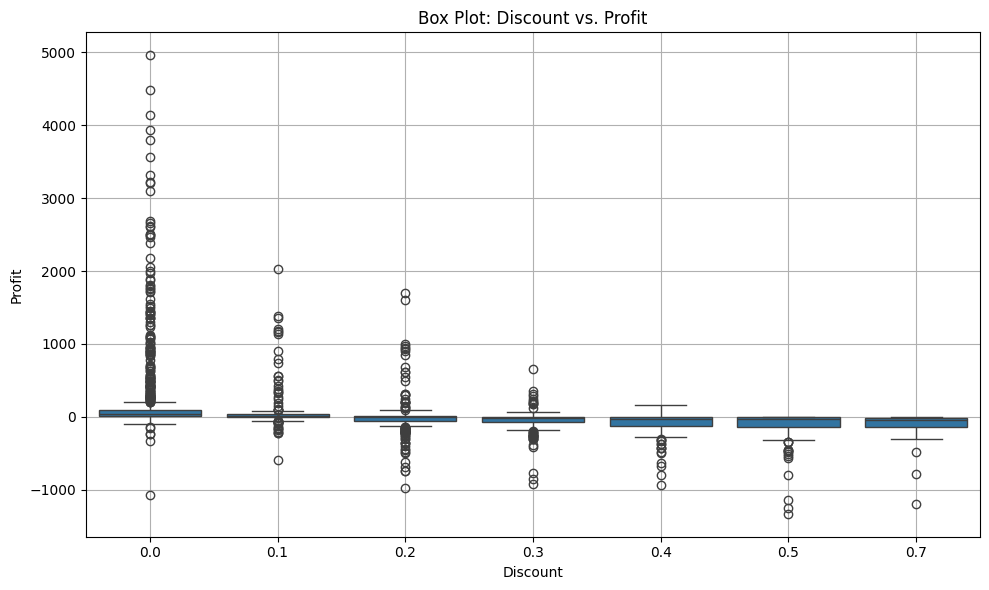

Total profit by discount:


,Profit
Discount,
0.0,188711.07
0.1,16651.51
0.2,-2972.15
0.3,-9265.52
0.4,-13947.58
0.5,-13736.79
0.7,-7917.50


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
sns.boxplot(x='Discount', y='Profit', data=df)
plt.title('Box Plot: Discount vs. Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()
print('Total profit by discount:')
display(df.groupby('Discount')['Profit'].sum().round(2))


## 5. Category and region analysis

Compare total Sales and Profit by category. Profit margin is total Profit divided by total Sales. The regional chart compares total sales by region.


In [ ]:
category_summary = (
    df.groupby("Category")[["Sales", "Profit"]]
      .sum()
)
category_summary["Profit Margin"] = (
    category_summary["Profit"] / category_summary["Sales"] * 100
)
category_summary

,Sales,Profit,Profit Margin
Category,,,
Furniture,410695.39,-17824.00,-4.339956
Office Supplies,79408.12,8408.87,10.589433
Technology,1404765.75,166938.17,11.883702


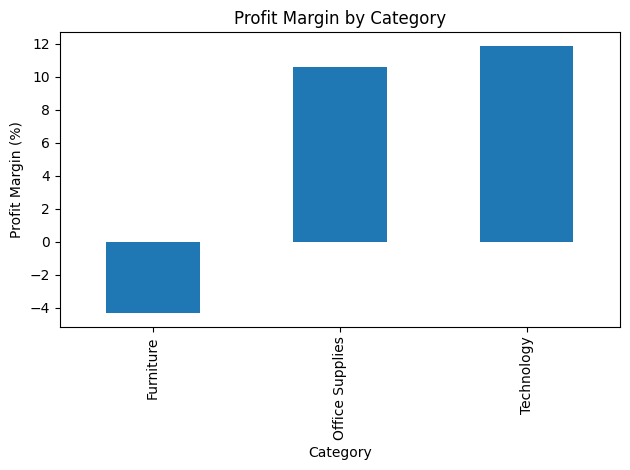

In [ ]:
category_summary["Profit Margin"].plot(
    kind="bar",
    title="Profit Margin by Category",
    ylabel="Profit Margin (%)"
)

plt.tight_layout()
plt.show()

In [ ]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_sales

,Sales
Region,
West,602214.30
East,492193.20
Central,435202.55
South,365259.21


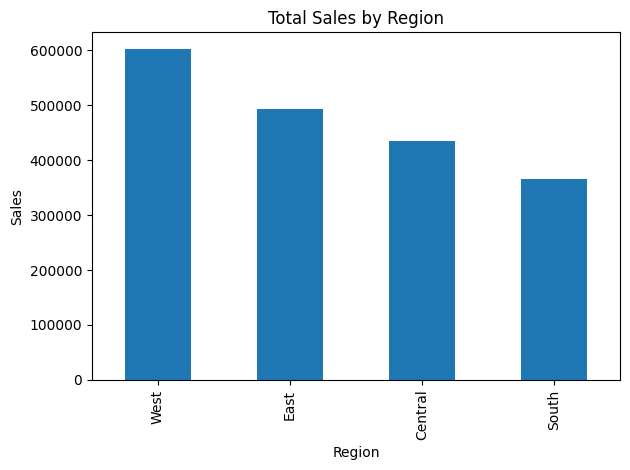

In [ ]:
region_sales.plot(
    kind="bar",
    title="Total Sales by Region",
    ylabel="Sales"
)

plt.tight_layout()
plt.show()

## 6. Monthly trends

The monthly chart helps identify peaks and unusually low months. With only a few years of data, treat possible seasonality as a pattern to investigate.


In [ ]:
monthly = (
    df.set_index("Order Date")[["Sales", "Profit"]]
      .resample("MS")
      .sum()
)

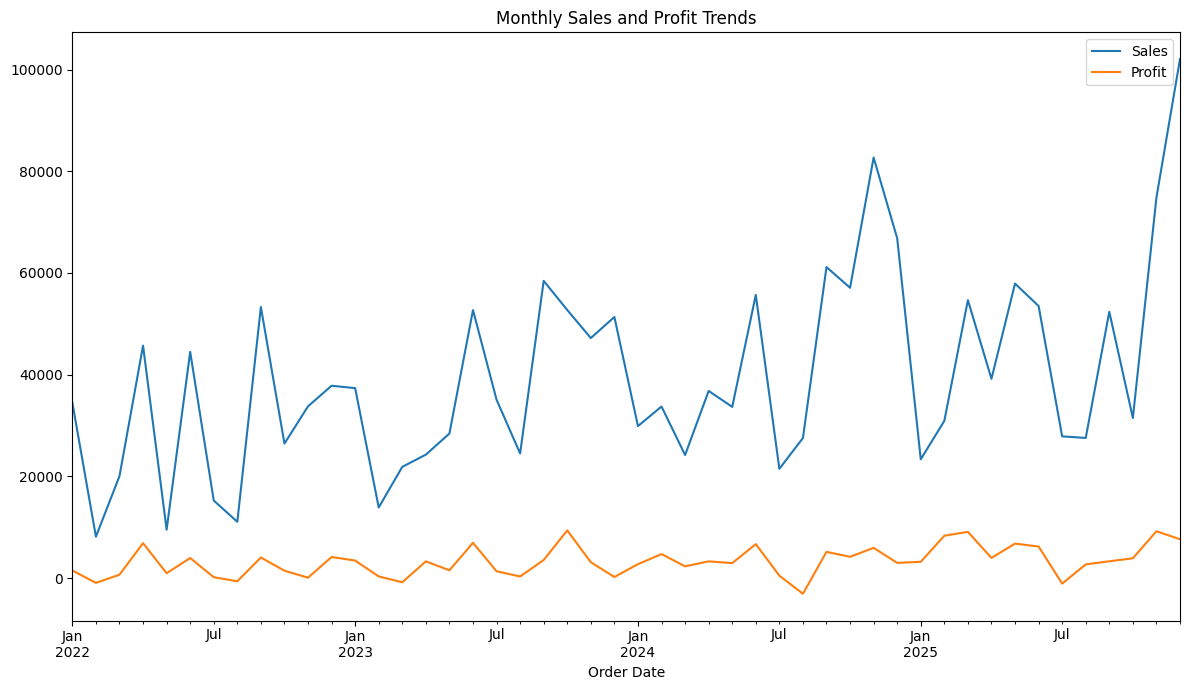

In [ ]:
monthly.plot(
    figsize=(12, 7),
    title="Monthly Sales and Profit Trends"
)
plt.tight_layout()
plt.show()

## 7. Correlation

The heatmap summarizes linear relationships among numeric fields. Correlation does not establish cause and effect.


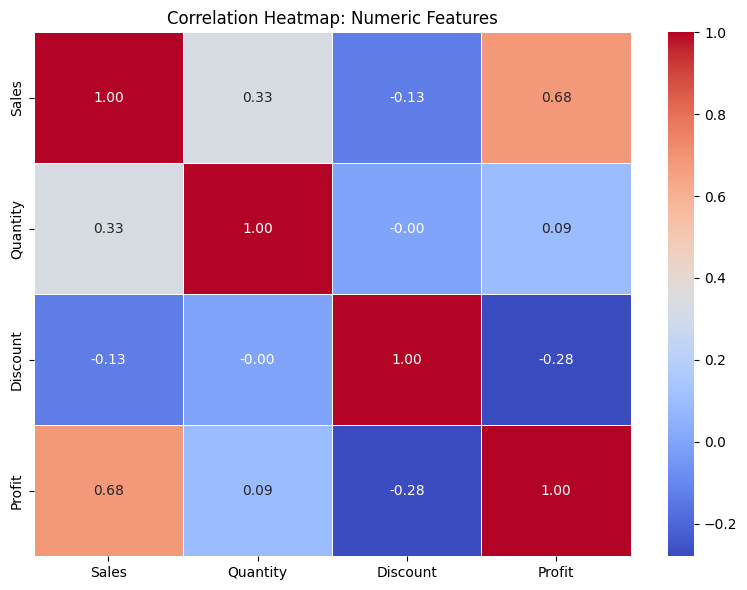

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
numeric_cols = df[['Sales', 'Quantity', 'Discount', 'Profit']]
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap: Numeric Features')
plt.tight_layout()
plt.show()


## 8. Key insights

1. **Technology leads sales and profit:** about $1.40M  in sales and $166.9K in profit, with an 11.9% profit margin. *(Category margin chart.)*
2. **Furniture loses money overall:** about $410.7K  in sales but a $17.8K loss and a -4.3% margin. *(Category margin chart and category summary.)*
3. **Sales and profit generally move together, but not always:** their correlation is about 0.68, and the scatter plot shows exceptions. *(Scatter plot and heatmap.)*
4. **Higher discount groups tend to have weaker profit:** discounts of 20% or more show negative total profit in this sample. This is an association, not proof that discounts caused the losses. *(Discount vs Profit box plot.)*
5. **Monthly sales vary:** the largest month is December 2025 at about $102K;  February   is about $8.2K. More years are needed to confirm a seasonal pattern. *(Monthly trend chart.)*

## Questions to investigate next

- What is driving Furniture losses, especially Tables and Bookcases?
- Do sales peaks repeat each year, or are they driven by a few large orders?


